## 3. Data Preprocessing

The cleaned dataset is prepared for machine learning while keeping the same feature choices used in the main notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib

df_clean = pd.read_csv("../data/02_cleaned_data.csv")

print("Cleaned data loaded successfully!")
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Cleaned data loaded successfully!
Shape: (24700, 19)
Missing values: 0
Duplicate rows: 0


In [2]:
y = df_clean["loan_recovered"]

## Correlation Analysis

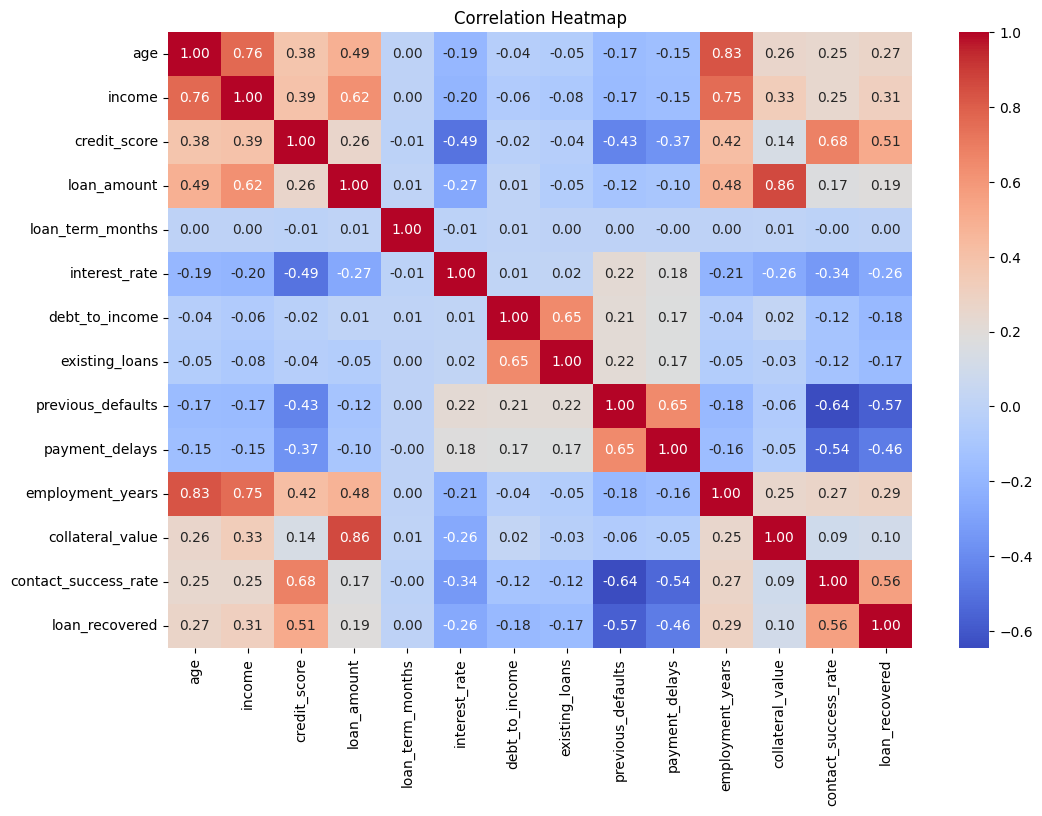

In [3]:
plt.figure(figsize=(12, 8))

correlation = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

## Feature Selection and Target Separation

In [4]:
X = df_clean.drop(
    columns=["customer_id", "customer_name", "loan_id", "loan_recovered"]
)

y = df_clean["loan_recovered"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (24700, 15)
Target shape: (24700,)


In [5]:
print("Features:")
print(X.columns.tolist())

Features:
['age', 'income', 'employment_type', 'credit_score', 'loan_amount', 'loan_term_months', 'interest_rate', 'debt_to_income', 'existing_loans', 'previous_defaults', 'payment_delays', 'employment_years', 'collateral_value', 'loan_purpose', 'contact_success_rate']


In [6]:
print("Target:")
print(y.name)

Target:
loan_recovered


In [7]:
numeric_features = [
    "age",
    "income",
    "credit_score",
    "loan_amount",
    "loan_term_months",
    "interest_rate",
    "debt_to_income",
    "existing_loans",
    "previous_defaults",
    "payment_delays",
    "employment_years",
    "collateral_value",
    "contact_success_rate"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 13
Categorical features: 2


## Categorical Feature Encoding

In [8]:
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True
)

print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

Original feature count: 15
Encoded feature count: 21


In [9]:
print(X_encoded.columns.tolist())

['age', 'income', 'credit_score', 'loan_amount', 'loan_term_months', 'interest_rate', 'debt_to_income', 'existing_loans', 'previous_defaults', 'payment_delays', 'employment_years', 'collateral_value', 'contact_success_rate', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-Employed', 'employment_type_Unemployed', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'loan_purpose_Vehicle']


In [10]:
drop_first=True

In [11]:
X_encoded.head()

,age,income,credit_score,loan_amount,loan_term_months,interest_rate,debt_to_income,existing_loans,previous_defaults,payment_delays,...,collateral_value,contact_success_rate,employment_type_Contract,employment_type_Salaried,employment_type_Self-Employed,employment_type_Unemployed,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_purpose_Vehicle
0,50.0,94000.0,641.0,480000.0,48,7.84,0.302,1.0,0.0,0.0,...,355000.0,0.688,False,True,False,False,False,False,False,True
1,40.0,61000.0,545.0,155000.0,48,11.51,0.206,0.0,1.0,2.0,...,5000.0,0.400,False,True,False,False,False,False,True,False
2,60.0,141500.0,740.0,1075000.0,18,8.10,0.190,0.0,0.0,0.0,...,595000.0,0.903,False,True,False,False,False,False,False,True
3,37.0,48500.0,602.0,195000.0,18,9.33,0.275,2.0,0.0,0.0,...,135000.0,0.486,False,False,True,False,False,False,False,True
4,31.0,45000.0,669.0,220000.0,60,9.99,0.280,2.0,0.0,1.0,...,25000.0,0.506,False,True,False,False,False,False,True,False


In [12]:
print("Final feature matrix shape:", X_encoded.shape)

Final feature matrix shape: (24700, 21)


In [13]:
print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_encoded.shape[1])

Original feature count: 15
Encoded feature count: 21


## Train-Test Split

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (19760, 21)
X_test: (4940, 21)
y_train: (19760,)
y_test: (4940,)


In [15]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64

Testing target distribution:
loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64


## Feature Scaling

In [16]:
# Handle missing numerical values using median imputation

numeric_columns = [
    "income",
    "debt_to_income",
    "payment_delays",
    "credit_score",
    "contact_success_rate",
    "previous_defaults",
    "collateral_value",
    "loan_amount"
]

for column in numeric_columns:
    median_value = X_train[column].median()
    X_train[column] = X_train[column].fillna(median_value)
    X_test[column] = X_test[column].fillna(median_value)

print("Missing values handled successfully!")
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

Missing values handled successfully!
Missing values in X_train: 0
Missing values in X_test: 0


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (19760, 21)
Testing data shape: (4940, 21)


In [18]:
print("Missing values in X_train_scaled:", np.isnan(X_train_scaled).sum())
print("Missing values in X_test_scaled:", np.isnan(X_test_scaled).sum())

Missing values in X_train_scaled: 0
Missing values in X_test_scaled: 0


### Saving the processed data

In [19]:

processed_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "X_train_scaled": X_train_scaled,
    "X_test_scaled": X_test_scaled,
    "scaler": scaler,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(processed_data, "../data/03_processed_data.pkl")
print("Processed data saved successfully!")


Processed data saved successfully!


## Class Imbalance Analysis

Class imbalance occurs when the number of observations in one target class
is significantly different from another class.

In this dataset, approximately 65% of loans are recovered and 35% are not
recovered. Therefore, the dataset has a moderate class imbalance.

Since the minority class still represents a substantial portion of the
dataset, no oversampling or undersampling technique was applied.

Instead, stratified train-test splitting was used to preserve the same
class distribution in both training and testing datasets.

Recall was also used as an important evaluation metric because correctly
identifying recovery cases is important for the debt recovery strategy.

In [20]:
print("Target Class Distribution:")
print(y.value_counts())

print("\nTarget Class Percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Target Class Distribution:
loan_recovered
1    16055
0     8645
Name: count, dtype: int64

Target Class Percentage:
loan_recovered
1    65.0
0    35.0
Name: proportion, dtype: float64


In [21]:
print("Processed training shape:", X_train.shape)
print("Processed testing shape:", X_test.shape)
print("Missing values in training:", X_train.isna().sum().sum())
print("Missing values in testing:", X_test.isna().sum().sum())

Processed training shape: (19760, 21)
Processed testing shape: (4940, 21)
Missing values in training: 0
Missing values in testing: 0
